# Tools - reducing graph (MEMB algorithm)

This notebook shows how to reduce (coarsen) a graph by using the Maximum-Excluded Mass Burning (MEMB) algorithm. This algorithm computes a lighter graph, with less nodes and edges, by regrouping the nodes of the original graph in clusters, which are the output nodes, and by linking these clusters according to the edges present in the original graph.

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
# import scipy
import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
import pyvista as pv

# Choose backend for pyvista with jupyter
# ---------------------------------------
pv.set_jupyter_backend('static') # static plots
# pv.set_jupyter_backend('trame')  # 3D-interactive plots

# Notes:
# -> ignored if run in a standard python shell
# -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.7


In [5]:
# Define a function to generate a segmented color map
import matplotlib

def seg_cmap(ncol, cmap=plt.cm.rainbow, t0=0.1, t1=0.9):
    """Function to define a segmented color map."""
    # - extract some colors from the color map `cmap`
    colors = [cmap(i) for i in range(int(t0*cmap.N), int(t1*cmap.N))]
    # - create the new segmented color map
    segmented_cmap = matplotlib.colors.LinearSegmentedColormap.from_list('Segmented cmap', colors, ncol)
    return segmented_cmap    

## Maximum Excluded Mass Burning (MEMB) algorithm

The function `kn.tools.reduce_graph_memb` performs the MEMB algorithm.

For a graph `g` (`networkx.Graph` object, with position as node attributes ('pos')) and a given radius `r`, the algorithm divides the set of graph nodes in clusters such that:
- each cluster is composed of connected nodes
- every node `u` in a cluster is at a distance of maximum `r` to a central node `c` (in the cluster) ; the distance is the distance of the shortest path where each edge has a length of one (note that specific edge weight can be considered for distance)

Then, a reduced graph `g_red` can be computed, where every node (vertex) corresponds to one cluster, and an edge links two nodes if there exists an edge between the two corresponding clusters. The node attributes (properties) on the reduced graph is set to the mean of the attributes at the nodes of the corresponding cluster or to the attributes of the central node of the cluster (see parameter `node_attr_mode`).

Moreover, using the parameter `node_group_id_dict` (optional), one can assign a integer group id to every node of the input graph and the MEMB algorithm is applied in such a way that nodes with different group ids will be grouped in different clusters ; this can be used to add some control on the graph reduction.

### Optional outputs
The function `kn.tools.reduce_graph_memb` returns the reduced graph, and optionally:
- if parameter `return_new_id_dict=True`: a dictionary where the keys are the node labels of the input graph and the values are the corresponding node labels in the output graph, i.e. the id of the cluster containing the node of the input graph
- if parameter `return_orig_id_dict=True`: a dictionary where the keys are the node labels of the output graph and the values are the lists of the node labels of the input graph in the corresponding clusters
- if parameter `return_center_id_dict=True`: a dictionary where the keys are the node labels of the output graph and the  values are the node ids (labels) in the input graph of the cluster center (according to MEMB algorithm)
- if parameter `return_medoid_id_dict=True`: a dictionary where the keys are the node labels of the output graph and the values are the node ids (labels) in the input graph of the cluster medoids; the medoid of the subgraph of the input graph induced by the nodes in a considered cluster is computed, where the medoid is the node realizing the minimum of the sum of the shortest path lengths (wrt. edge weight) to any other node
- if parameter `return_cluster_diameter_dict=True`: a dictionary where the keys are the node labels of the output graph and the values are the diameters of the cluster (box), i.e. the maximal distance (in the original graph, wrt. edge weight) between two nodes in the cluster

## Simple example on a small graph 2D
A 2D example - a graph generated from a Delaunay triangulation of points.

In [6]:
# Options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'linewidths'  : 1,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

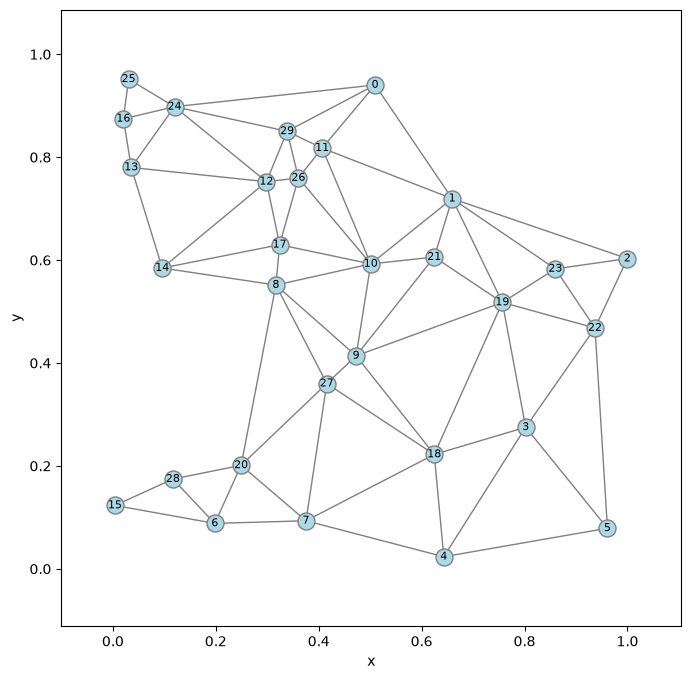

In [7]:
# Number of points and seed
npoints = 30
seed = 35306

# Generate random points uniformly in [0, 1] x [0, 1]
np.random.seed(seed)
points = np.random.random(size=(npoints, 2))

# Generate 2D graph from Delaunay triangulation of the points,
# edges whose length are less (resp. greater) than a mininmal (resp. maximal) valuse are removed
g = kn.misc.graph_from_delaunay_tri(points,min_edge_len=0.01, max_edge_len=0.4)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

- Add a node with a string as label to check that the developed algorithms work property

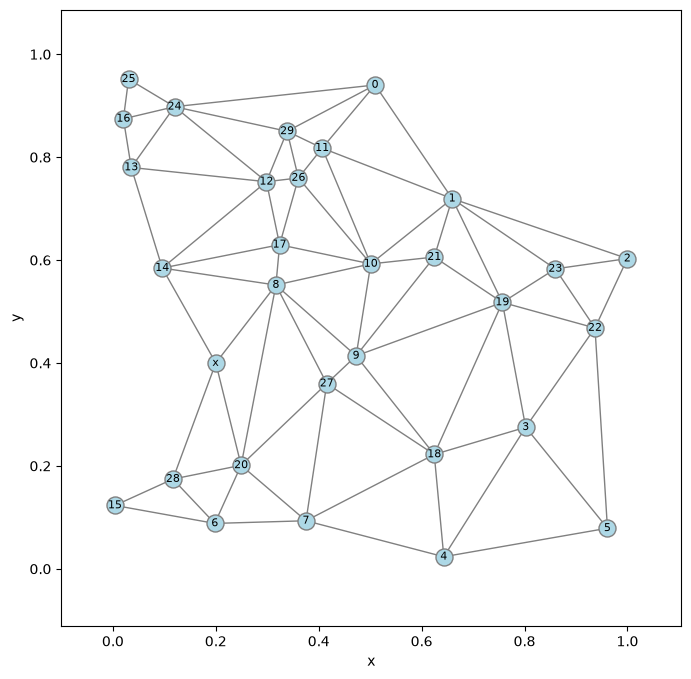

In [8]:
# Add a node with label 'x' and some edges
g.add_node('x')
g.nodes['x']['pos'] = np.array([0.2, 0.4])
g.add_edges_from([('x', i) for i in [8, 14, 28, 20]])

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

### Run MEMB


In [9]:
# Compute reduced graph `g_red` and additional dictionaries
radius = 1
edge_weight = None
node_attr_mode = 'mean'
# node_attr_mode = 'center'
# node_attr_mode = 'medoid'
node_group_id_dict = None

t1 = time.time()
g_red, new_id_dict, orig_id_dict, center_id_dict, medoid_id_dict, cluster_diameter_dict = \
    kn.tools.reduce_graph_memb(
        g, 
        r=radius,
        edge_weight=edge_weight,
        node_attr_mode=node_attr_mode,
        node_group_id_dict=node_group_id_dict,
        return_new_id_dict=True, 
        return_orig_id_dict=True,
        return_center_id_dict=True, 
        return_medoid_id_dict=True,
        return_cluster_diameter_dict=True,
        seed=8932,
        verbose=2)
t2 = time.time()
print(f'Elapsed time : {t2-t1:.2g} sec')

# Set properties to nodes in input graph
nx.set_node_attributes(g, new_id_dict, 'new_id')

# Set properties to nodes in reduced graph
nx.set_node_attributes(g_red, orig_id_dict, 'orig_id')
nx.set_node_attributes(g_red, center_id_dict, 'center_id')
nx.set_node_attributes(g_red, medoid_id_dict, 'medoid_id')
nx.set_node_attributes(g_red, cluster_diameter_dict, 'cluster_diameter')

MEMB (unweighted graph) - Computing shortest path length for any pair of nodes (with cutoff 1)...
MEMB - Selecting node centers...
... Number of centers:     0, Number of uncovered nodes:     31
... Number of centers:     1, Number of uncovered nodes:     23
... Number of centers:     2, Number of uncovered nodes:     16
... Number of centers:     3, Number of uncovered nodes:     10
... Number of centers:     4, Number of uncovered nodes:      4
... Number of centers:     5, Number of uncovered nodes:      2
... Number of centers:     6, Number of uncovered nodes:      1
MEMB - Number of centers: 7
MEMB - Assigning new id to node centers...
MEMB - Computing distance to node centers for all nodes...
MEMB - Assigning new id for non-center nodes...
MEMB - Building the reduced graph...
Elapsed time : 0.0026 sec


In [10]:
# Options for plot of 2D graph
options_g = {
    'node_size'   : 150,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    # 'cmap'        : 'tab20c',    # node color map (for attribute values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,       # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

options_g_red = {
    'node_size'   : 150,         # node size
    'linewidths'  : 2,           # node border width       
    'edgecolors'  : 'tab:red',   # node border color
    'node_color'  : 'none',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'tab:red',   # edge color (default - if no attribute is specified or for nan values)
    # 'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Color map and bounds for "new id"
cmap = seg_cmap(g_red.number_of_nodes(), cmap=plt.cm.tab20c)
vmin, vmax =-0.5, g_red.number_of_nodes()-0.5


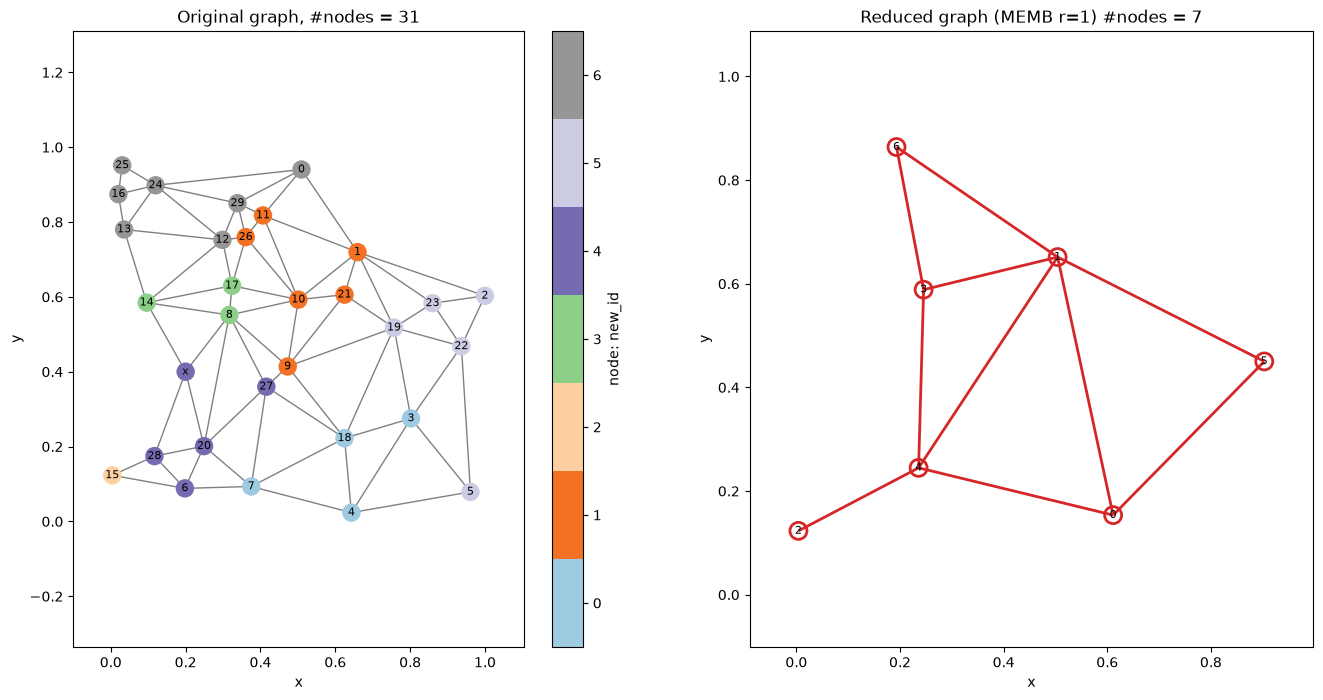

In [11]:
plt.subplots(1,2, figsize=(16, 8))

plt.subplot(1,2,1)
kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g)
plt.title(f'Original graph, #nodes = {g.number_of_nodes()}')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_red, with_labels=True, **options_g_red)
plt.title(f'Reduced graph (MEMB r={radius}) #nodes = {g_red.number_of_nodes()}')

plt.show()


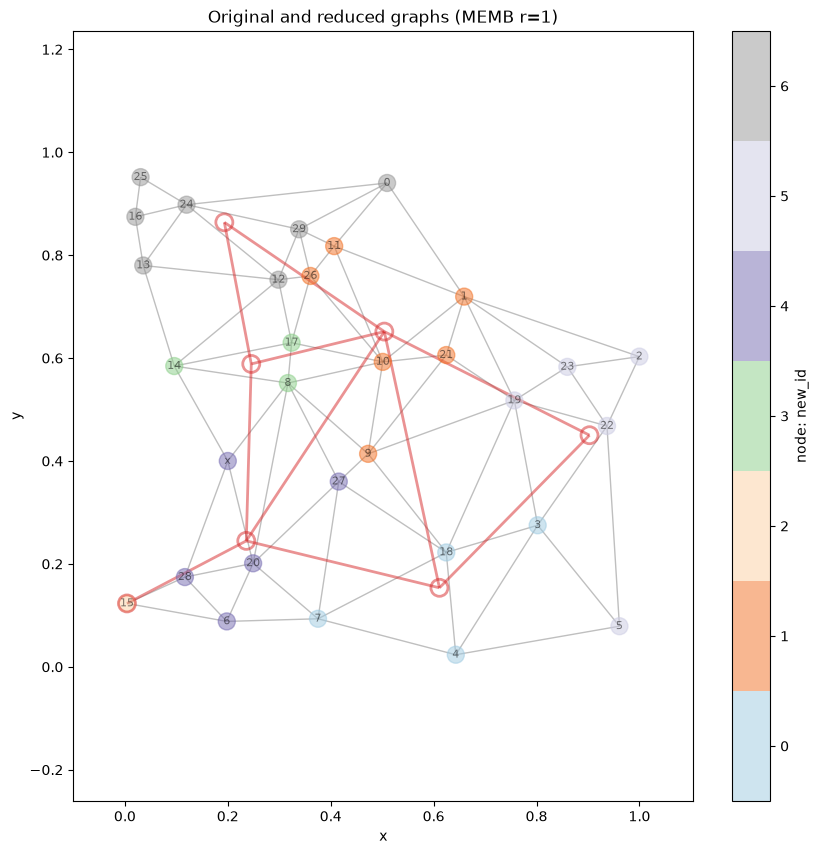

In [12]:
plt.figure(figsize=(10, 10))

kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=0.5)
kn.view.plot_graph2d(g_red, with_labels=False, **options_g_red, alpha=.5)
plt.title(f'Original and reduced graphs (MEMB r={radius})')

plt.show()


#### Optional outputs of the function `kn.tools.reduce_graph_memb`

In [13]:
# orig_id_dict: mapping from new node label to original node label
orig_id_dict

{0: [3, 4, 7, 18],
 1: [1, 9, 10, 11, 21, 26],
 2: [15],
 3: [8, 14, 17],
 4: [6, 20, 27, 28, 'x'],
 5: [2, 5, 19, 22, 23],
 6: [0, 12, 13, 16, 24, 25, 29]}

In [14]:
# new_id_dict: mapping from original node label to new node label
new_id_dict

{0: 6,
 1: 1,
 2: 5,
 3: 0,
 4: 0,
 5: 5,
 6: 4,
 7: 0,
 8: 3,
 9: 1,
 10: 1,
 11: 1,
 12: 6,
 13: 6,
 14: 3,
 15: 2,
 16: 6,
 17: 3,
 18: 0,
 19: 5,
 20: 4,
 21: 1,
 22: 5,
 23: 5,
 24: 6,
 25: 6,
 26: 1,
 27: 4,
 28: 4,
 29: 6,
 'x': 4}

In [15]:
# center_id_dict: mapping from new node label to cluster MEMB center node label in the original graph
center_id_dict

{0: 4, 1: 10, 2: 15, 3: 17, 4: 20, 5: 22, 6: 24}

In [16]:
# medoid_id_dict: mapping from new node label to cluster medoid node label in the original graph
medoid_id_dict

{0: 18, 1: 10, 2: 15, 3: 8, 4: 20, 5: 22, 6: 24}

In [17]:
# cluster_diameter_dict: mapping from new node label to diameter of the cluster in the original graph
cluster_diameter_dict

{0: 2, 1: 2, 2: 0, 3: 1, 4: 2, 5: 2, 6: 2}

#### Changing position of the output graph nodes

In [18]:
# Set position of nodes in reduced graph to the position of the nodes of the input graph corresponding to the cluster MEMB centers
g_red_center = g_red.copy()

for u in g_red_center.nodes():
    g_red_center.nodes[u]['pos'] = g.nodes[center_id_dict[u]]['pos']

# Note: `g_red_center` may also be obtained by running `kn.tools.reduce_graph_memb` as above but with parameter `node_attr_mode='center'`.

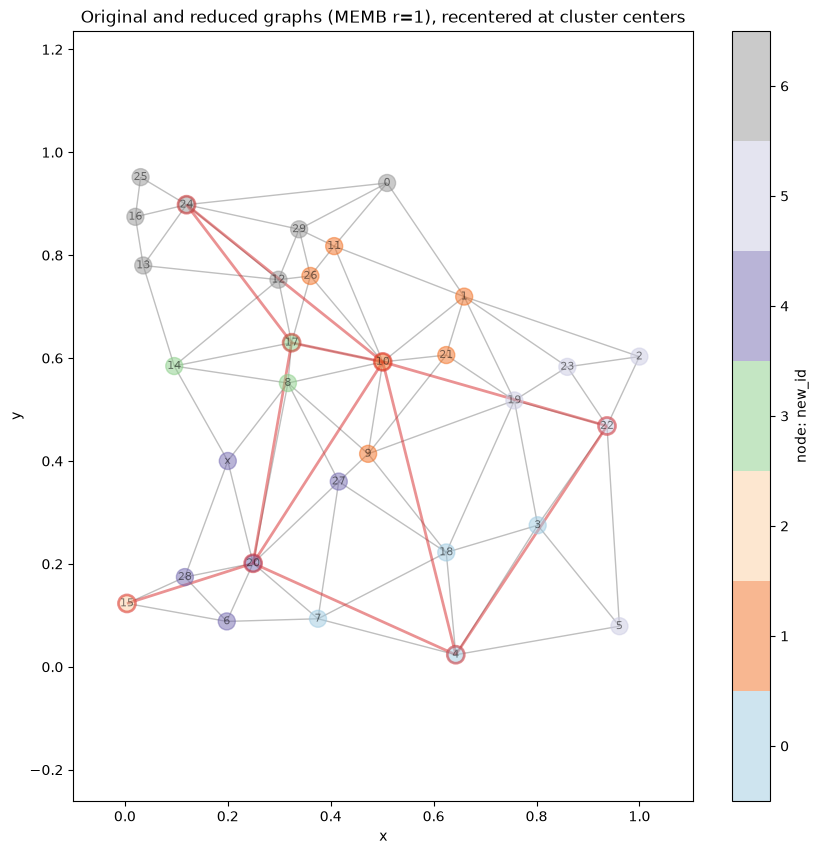

In [19]:
plt.figure(figsize=(10, 10))

kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=.5)
kn.view.plot_graph2d(g_red_center, with_labels=False, **options_g_red, alpha=.5)
plt.title(f'Original and reduced graphs (MEMB r={radius}), recentered at cluster centers')

plt.show()


In [20]:
# Set position of nodes in reduced graph to the position of the medoids of the clusters
g_red_medoid = g_red.copy()

for u in g_red_medoid.nodes():
    g_red_medoid.nodes[u]['pos'] = g.nodes[medoid_id_dict[u]]['pos']

# Note: `g_red_medoid` may also be obtained by running `kn.tools.reduce_graph_memb` as above but with parameter `node_attr_mode='medoid'`.

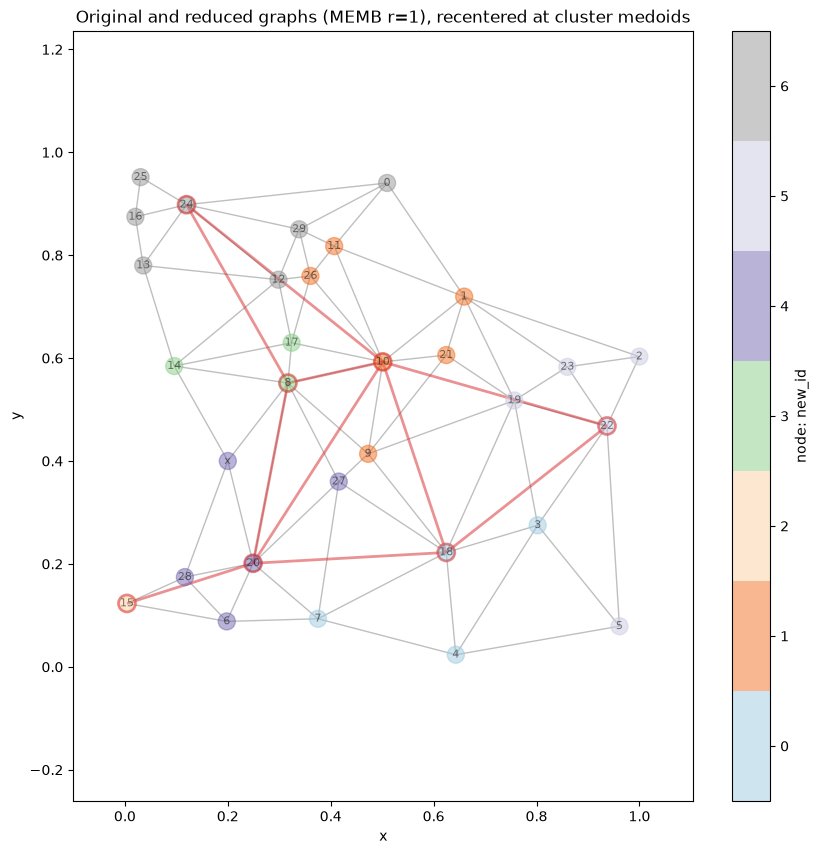

In [21]:
plt.figure(figsize=(10, 10))

kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=.5)
kn.view.plot_graph2d(g_red_medoid, with_labels=False, **options_g_red, alpha=.5)
plt.title(f'Original and reduced graphs (MEMB r={radius}), recentered at cluster medoids')

plt.show()


### Fixing some nodes in the input graph

Assigning a group id to graph nodes allows to ensures that nodes with different group ids will be grouped in different clusters. For that the parameter `node_group_id_dict` is used and consists of a dictionary where the keys are input graph node labels, and the values an integer group id; the id 0 is the default id attached to any node that is not listed in the keys.

In particular, a (positive) group id used for only once node, implies that this node will be fixed in the reduced graph.

In [22]:
# Compute reduced graph `g_red` and additional dictionaries
radius = 1
edge_weight = None
node_attr_mode = 'mean'
# node_attr_mode = 'center'
# node_attr_mode = 'medoid'
node_group_id_dict = {15: 1, 5: 2, 2: 3, 25: 4}  # Fix nodes 15, 5, 2, and 25 in the reduced graph

t1 = time.time()
g_red, new_id_dict, orig_id_dict, center_id_dict, medoid_id_dict, cluster_diameter_dict = \
    kn.tools.reduce_graph_memb(
        g, 
        r=radius,
        edge_weight=edge_weight,
        node_attr_mode=node_attr_mode,
        node_group_id_dict=node_group_id_dict,
        return_new_id_dict=True, 
        return_orig_id_dict=True,
        return_center_id_dict=True, 
        return_medoid_id_dict=True,
        return_cluster_diameter_dict=True,
        seed=8932,
        verbose=2)
t2 = time.time()
print(f'Elapsed time : {t2-t1:.2g} sec')

# Set properties to nodes in input graph
nx.set_node_attributes(g, new_id_dict, 'new_id')

# Set properties to nodes in reduced graph
nx.set_node_attributes(g_red, orig_id_dict, 'orig_id')
nx.set_node_attributes(g_red, center_id_dict, 'center_id')
nx.set_node_attributes(g_red, medoid_id_dict, 'medoid_id')
nx.set_node_attributes(g_red, cluster_diameter_dict, 'cluster_diameter')

MEMB (unweighted graph) - Computing shortest path length for any pair of nodes (with cutoff 1)...
MEMB - Selecting node centers...
... Number of centers:     0, Number of uncovered nodes:     31
... Number of centers:     1, Number of uncovered nodes:     23
... Number of centers:     2, Number of uncovered nodes:     16
... Number of centers:     3, Number of uncovered nodes:     10
... Number of centers:     4, Number of uncovered nodes:      7
... Number of centers:     5, Number of uncovered nodes:      5
... Number of centers:     6, Number of uncovered nodes:      4
... Number of centers:     7, Number of uncovered nodes:      3
... Number of centers:     8, Number of uncovered nodes:      2
... Number of centers:     9, Number of uncovered nodes:      1
MEMB - Number of centers: 10
MEMB - Assigning new id to node centers...
MEMB - Computing distance to node centers for all nodes...
MEMB - Assigning new id for non-center nodes...
MEMB - Building the reduced graph...
Elapsed time 

In [23]:
# Options for plot of 2D graph
options_g = {
    'node_size'   : 150,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    # 'cmap'        : 'tab20c',    # node color map (for attribute values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,       # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

options_g_red = {
    'node_size'   : 150,         # node size
    'linewidths'  : 2,           # node border width       
    'edgecolors'  : 'tab:red',   # node border color
    'node_color'  : 'none',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'tab:red',   # edge color (default - if no attribute is specified or for nan values)
    # 'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Color map and bounds for "new id"
cmap = seg_cmap(g_red.number_of_nodes(), cmap=plt.cm.tab20c)
vmin, vmax =-0.5, g_red.number_of_nodes()-0.5


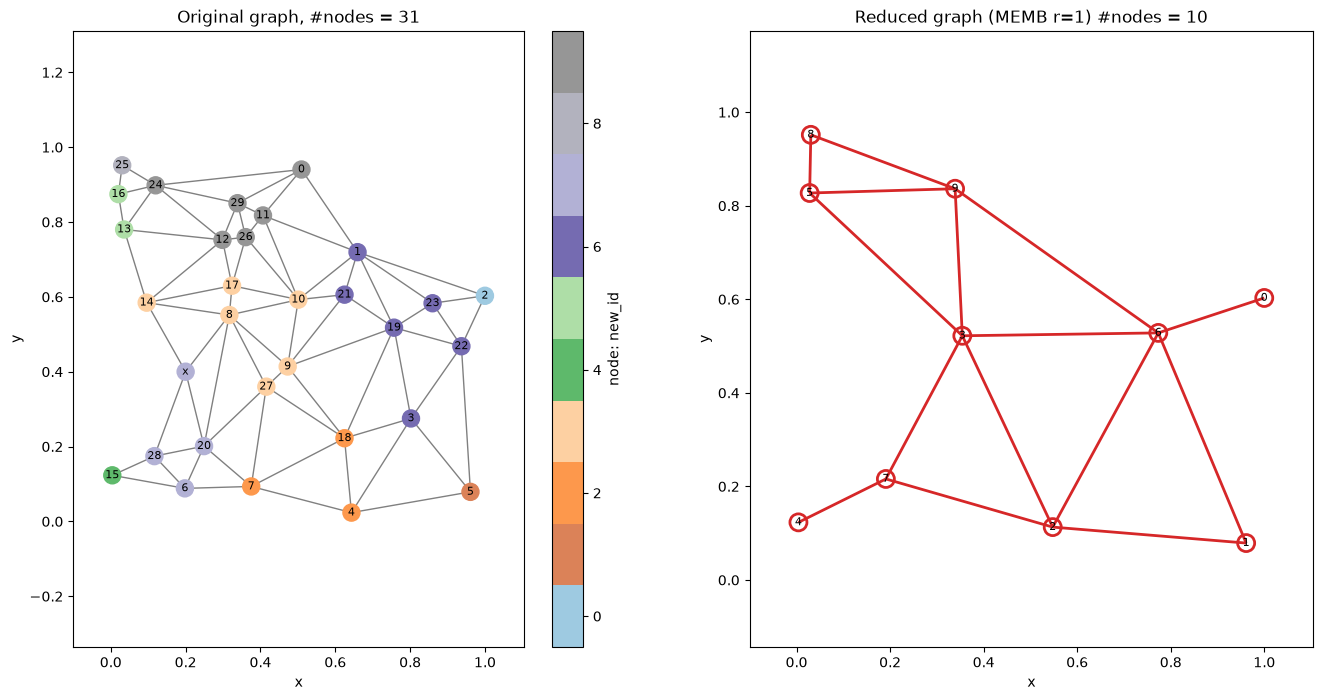

In [24]:
plt.subplots(1,2, figsize=(16, 8))

plt.subplot(1,2,1)
kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g)
plt.title(f'Original graph, #nodes = {g.number_of_nodes()}')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_red, with_labels=True, **options_g_red)
plt.title(f'Reduced graph (MEMB r={radius}) #nodes = {g_red.number_of_nodes()}')

plt.show()


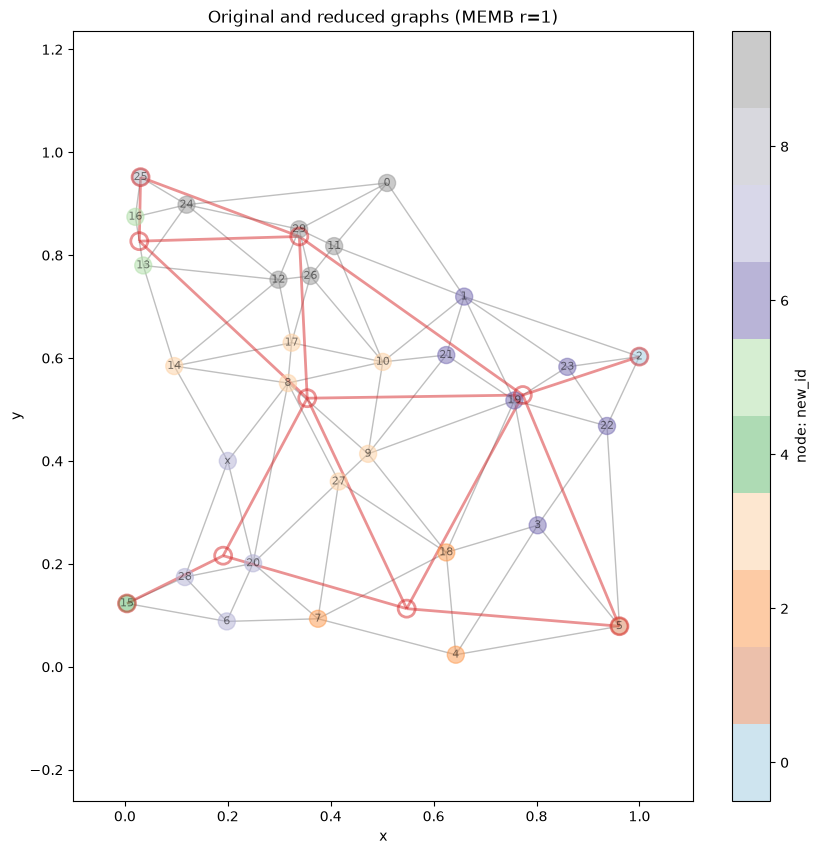

In [25]:
plt.figure(figsize=(10, 10))

kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=.5)
kn.view.plot_graph2d(g_red, with_labels=False, **options_g_red, alpha=.5)
plt.title(f'Original and reduced graphs (MEMB r={radius})')

plt.show()


### Multiple runs
The MEMB algorithm includes some steps with randomness. Hence, the resulting reduced graph is not unique, the number of nodes and their position may change.


In [26]:
# Compute reduced graph `g_red`, multiple runs
radius = 1
edge_weight = None
node_attr_mode = 'mean'
# node_attr_mode = 'center'
# node_attr_mode = 'medoid'
node_group_id_dict= None

nruns = 5

seed_list = 8932 + np.arange(5)
g_red_list = []
t1 = time.time()
for i in range(nruns):
    g_red_list.append(
        kn.tools.reduce_graph_memb(
            g, 
            r=radius,
            edge_weight=edge_weight,
            node_attr_mode=node_attr_mode,
            node_group_id_dict=node_group_id_dict,
            return_new_id_dict=False, 
            return_orig_id_dict=False,
            return_center_id_dict=False, 
            return_medoid_id_dict=False,
            return_cluster_diameter_dict=False,
            seed=seed_list[i],
            verbose=0
        )
    )
t2 = time.time()
print(f'Elapsed time ({nruns} runs) : {t2-t1:.2g} sec')


Elapsed time (5 runs) : 0.0026 sec


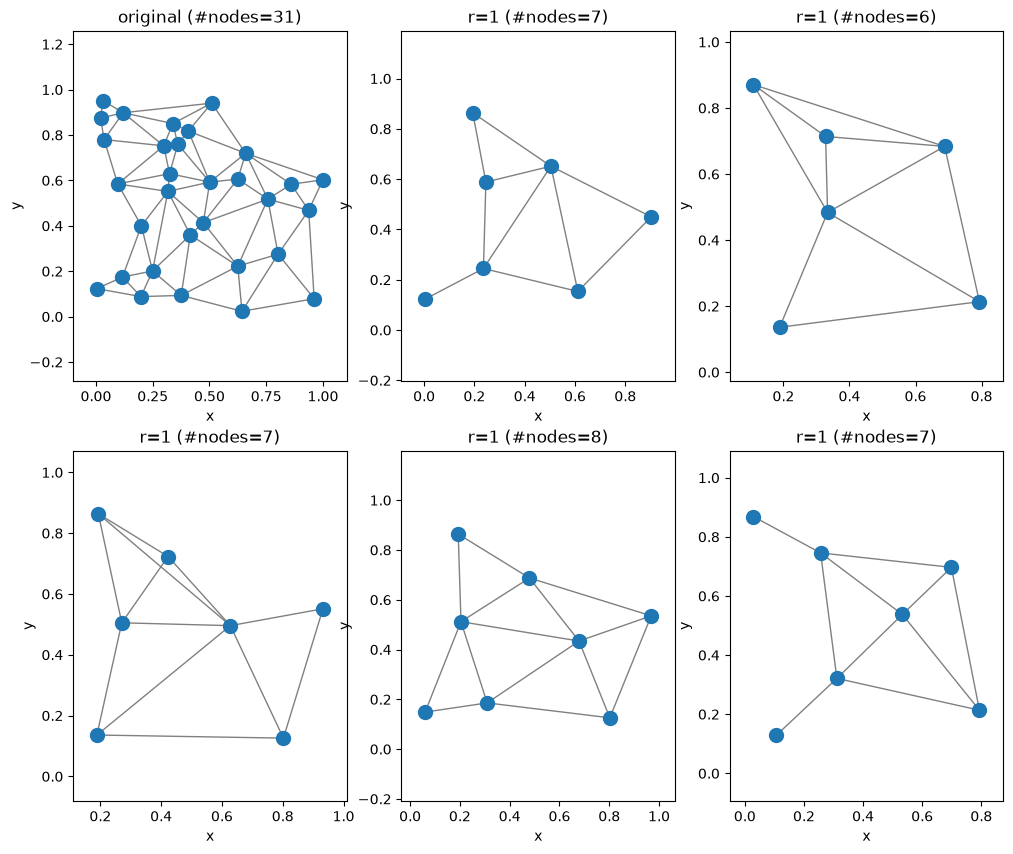

In [27]:
# Plot list of graphs - original graph and reduced graphs for a given radius
options = {
    'node_size'   : 100,         # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    # 'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

name_list = [f'original (#nodes={g.number_of_nodes()})'] + [f'r={radius:.3g} (#nodes={gi.number_of_nodes()})' for gi in g_red_list]
g_list = [g] + g_red_list

nn = len(g_list)
nc = min(3, nn)
nr = nn//nc + int(nn%nc > 0)

plt.subplots(nr, nc, figsize=(12, nr*5))
for i, (gi, name) in enumerate(zip(g_list, name_list)):
    plt.subplot(nr, nc, i+1)
    kn.view.plot_graph2d(gi, **options)
    plt.title(name)

for i in range(nn, nr*nc):
    plt.subplot(nr, nc, i+1)
    plt.axis('off')

plt.show()


## 3D example - real karst network

Example with the real karst network of Combe Bryon (Leysin, Switzerland).

### Load karst network
Load karst network from csv files. 

*Note. Other format are handled by karstnet.*

In [28]:
# Load KGraph object
basename = f'../data/CombeBryon_csv/CombeBryon'

kg = kn.from_csv(
        basename,
        suffix_nodes='_node_pos.csv', 
        suffix_edges='_edges.csv', 
        delimiter_nodes=';',  
        delimiter_edges=';',
        import_node_scalar_properties=True,
        import_edge_scalar_properties=True,
        verbose=True)

# Extract original graph
g = kg.graph

IMPORT ERROR: Could not import nodes (file: ../data/CombeBryon_csv/CombeBryon_node_pos.csv)


AttributeError: 'NoneType' object has no attribute 'keys'

In [ ]:
# # Equivalent 
# # ----------
# # - define networkx graph
# g = kn.io.networkx_from_csv(
#         basename,
#         suffix_nodes='_node_pos.csv', 
#         suffix_edges='_edges.csv', 
#         delimiter_nodes=';',  
#         delimiter_edges=';',
#         import_node_scalar_properties=True,
#         import_edge_scalar_properties=True,
#         verbose=True)
# # - then instanciate KGraph with
# kg = kn.from_networkx(g)
# # or
# Kg = kn.KGraph(None, None, None, networkx_graph=g, verbose=True)

### Plot original graph

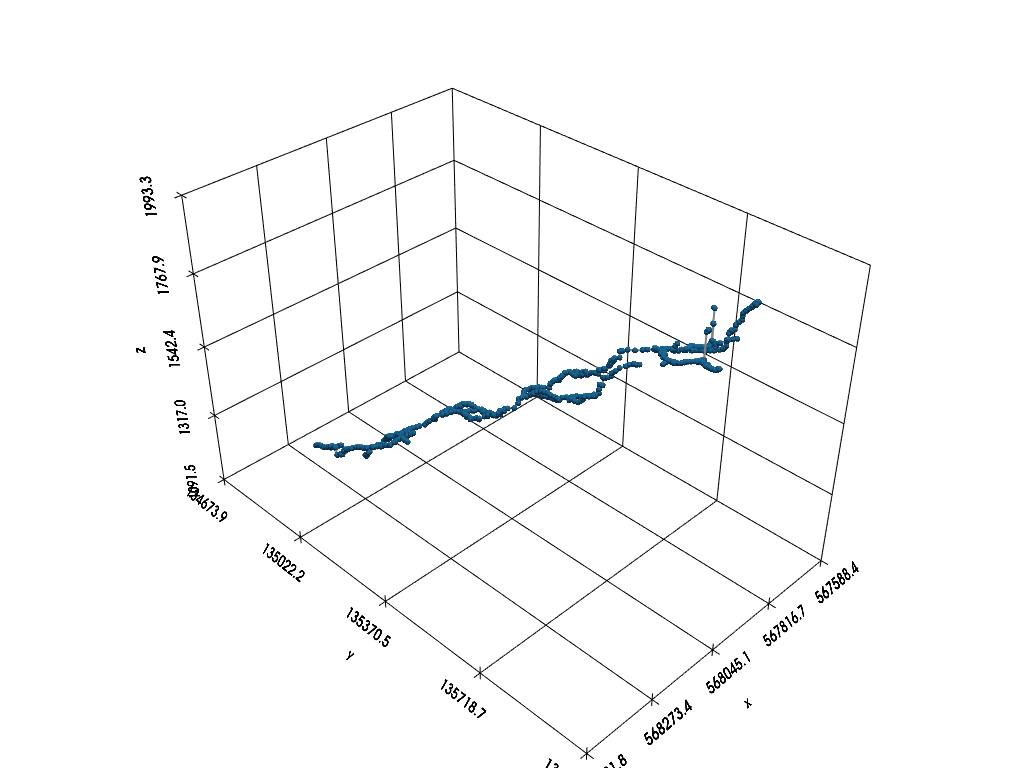

In [ ]:
#pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)

pp.show()


### Reduction of graph by Maximum Excluded Mass Burning (MEMB) algorithm

In [ ]:
# Compute reduced graph `g_red` and additional dictionaries
radius = 1
edge_weight = None
node_attr_list = ['pos']
node_attr_mode = 'mean'
# node_attr_mode = 'center'
# node_attr_mode = 'medoid'
node_group_id_dict = None

t1 = time.time()
g_red, new_id_dict, orig_id_dict, center_id_dict, medoid_id_dict, cluster_diameter_dict = \
    kn.tools.reduce_graph_memb(
        g, 
        r=radius,
        edge_weight=edge_weight,
        node_attr_list=node_attr_list,
        node_attr_mode=node_attr_mode,
        node_group_id_dict=node_group_id_dict,
        return_new_id_dict=True, 
        return_orig_id_dict=True,
        return_center_id_dict=True, 
        return_medoid_id_dict=True,
        return_cluster_diameter_dict=True,
        seed=893,
        verbose=1)
t2 = time.time()
print(f'Elapsed time : {t2-t1:.2g} sec')

# # Set properties to nodes in input graph
# nx.set_node_attributes(g, new_id_dict, 'new_id')

# # Set properties to nodes in reduced graph
# nx.set_node_attributes(g_red, orig_id_dict, 'orig_id')
# nx.set_node_attributes(g_red, center_id_dict, 'center_id')
# nx.set_node_attributes(g_red, medoid_id_dict, 'medoid_id')
# nx.set_node_attributes(g_red, cluster_diameter_dict, 'cluster_diameter')


MEMB (unweighted graph) - Computing shortest path length for any pair of nodes (with cutoff 1)...
MEMB - Selecting node centers...
MEMB - Number of centers: 243
MEMB - Assigning new id to node centers...
MEMB - Computing distance to node centers for all nodes...
MEMB - Assigning new id for non-center nodes...
MEMB - Building the reduced graph...
Elapsed time : 0.079 sec


### Plot result

- original graph and reduced graph on two separate figures

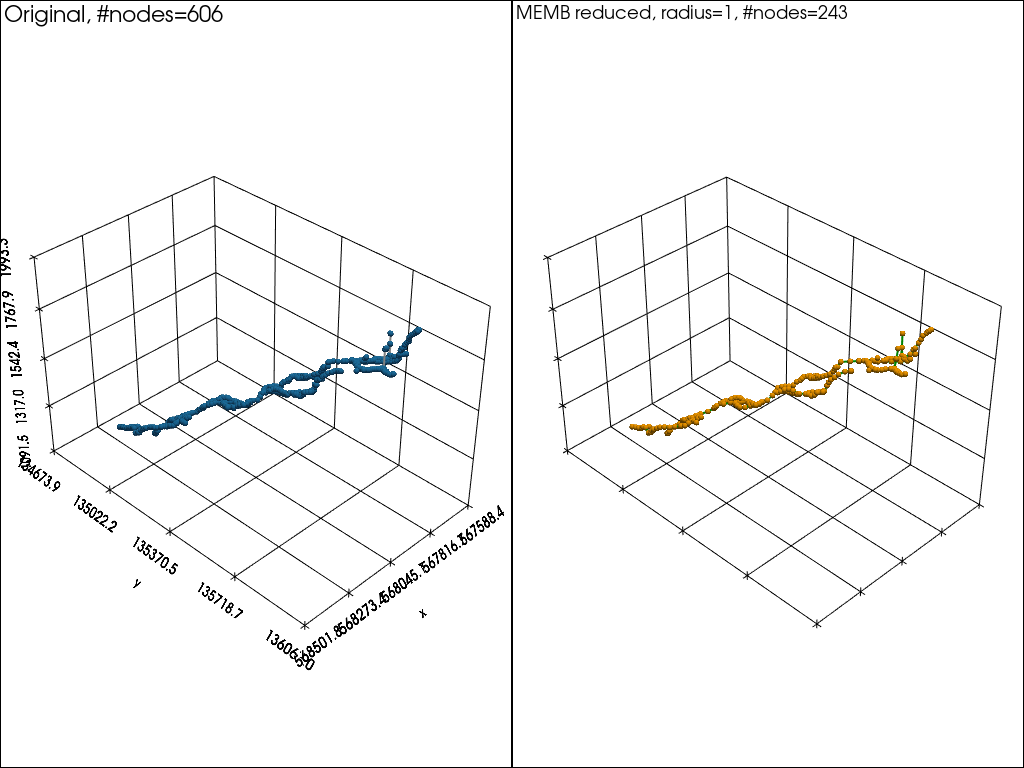

In [ ]:
#pp = pv.Plotter(shape=(1, 2), notebook=False) # plot in a pop-up window
pp = pv.Plotter(shape=(1, 2))

pp.subplot(0, 0)
kn.view.pv_plot_graph(
    g, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)
pp.add_text(f'Original, #nodes={g.number_of_nodes()}', font_size=12)

pp.subplot(0, 1)
kn.view.pv_plot_graph(
    g_red, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'orange'},
    options_edges={'line_width': 2, 'color': 'green'},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)
pp.add_text(f'MEMB reduced, radius={radius}, #nodes={g_red.number_of_nodes()}', font_size=12)

pp.link_views()
pp.show()


- original graph and reduced graph on same figure

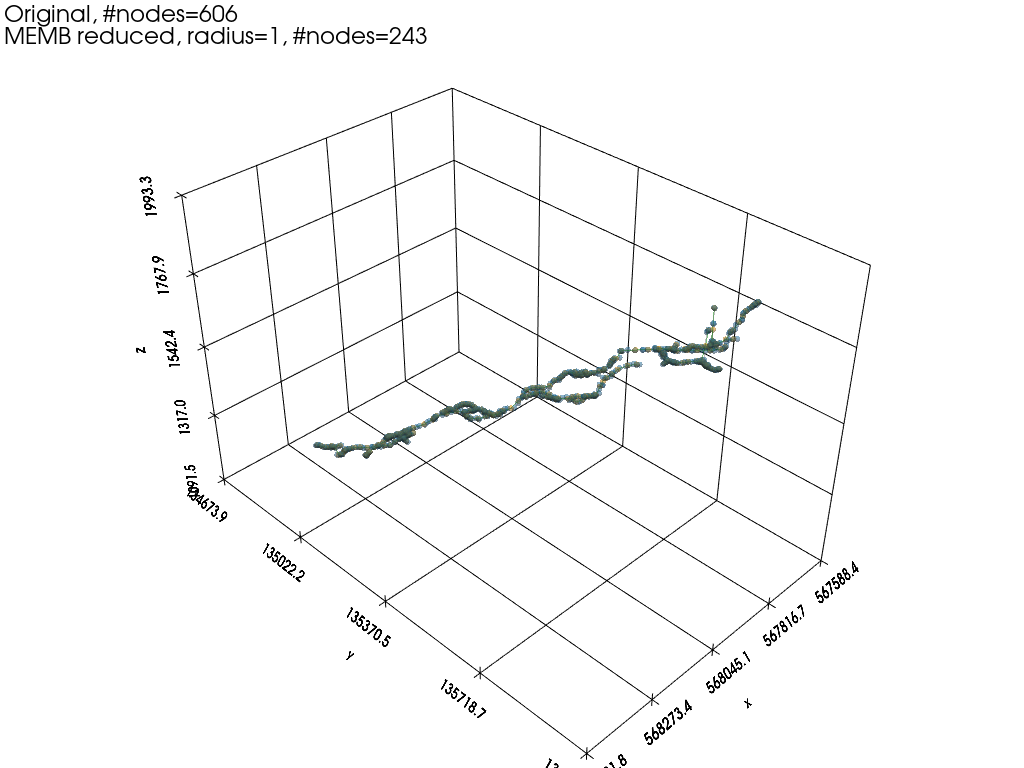

In [ ]:
# pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'tab:blue', 'opacity': 0.5},
    options_edges={'line_width': 1, 'color': 'gray', 'opacity': 0.5},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)
kn.view.pv_plot_graph(
    g_red, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'orange', 'opacity': 0.5},
    options_edges={'line_width': 1, 'color': 'green', 'opacity': 0.5},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)

pp.add_text(f'Original, #nodes={g.number_of_nodes()}\nMEMB reduced, radius={radius}, #nodes={g_red.number_of_nodes()}', font_size=12)

pp.show()
